# 単語ラティス・Viterbi アルゴリズムと CRF vs MEMM

書籍 第3章「系列ラベリング問題の解き方」（3-1-2 機械学習ベースの固有表現認識、3-2-3 機械学習ベースの形態素解析とラベルバイアス（p.99）、練習問題 1・2）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、以下の 2 つを数式どおりの最小実装で体験します。

1. **日本語単語分割の単語ラティス構築と Viterbi アルゴリズム（3-2）**: 最長一致法が失敗する曖昧文に対し、ノードコスト＋連接コストの最小化で大域最適解を求める。
2. **線形鎖 CRF vs MEMM とラベルバイアス問題（3-2-3、p.99）**: 同じ素性テンプレート・同じ正則化条件で両者を学習させ、局所正規化モデル（MEMM）が分岐の少ない状態に確率を奪われて訓練データすら誤る現象と、大域正規化（CRF）による解消を確認する。

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

---

## 1. 単語ラティスと Viterbi アルゴリズムによるコスト最小化（3-2）

形態素解析器（MeCab や SudachiPy など）は、入力文字列に対して辞書から取り出せる全候補単語の有向非巡回グラフ（**単語ラティス**）を構築し、各単語の**生起コスト（ノードコスト）**と品詞間の**連接コスト（エッジコスト）**の合計が最小になる経路を **Viterbi アルゴリズム（動的計画法）** で求めます。

まずは「貪欲な前方最長一致法」が誤分割してしまう典型的な曖昧文に対して、Viterbi アルゴリズムがどのように正解経路を見つけるか確認しましょう。

In [2]:
# 辞書: 表層形 -> [(品詞, ノードコスト), ...]
LEXICON = {
    "ここ": [("名詞", 2.0)],
    "で": [("助詞", 1.0)],
    "は": [("助詞", 1.0)],
    "では": [("助詞", 1.5)],
    "はきもの": [("名詞", 1.2)],
    "きもの": [("名詞", 2.2)],
    "を": [("助詞", 0.8)],
    "ぬぐ": [("動詞", 1.5)],
    "にわ": [("名詞", 1.6), ("名-数詞", 1.9)],
    "に": [("助詞", 0.9)],
    "はにわ": [("名詞", 3.6)],
    "にわとり": [("名詞", 1.4)],
    "が": [("助詞", 0.8)],
    "いる": [("動詞", 1.4)],
    "はは": [("名詞", 1.6)],
    "ははは": [("感動詞", 3.2)],
    "はな": [("名詞", 1.5)],
    "すき": [("形容動詞", 1.4)],
}

# 品詞間の連接コスト: (前品詞, 現品詞) -> コスト
DEFAULT_EDGE = 4.0
TRANS_COST = {
    ("BOS", "名詞"): 0.5, ("BOS", "動詞"): 1.8, ("BOS", "感動詞"): 2.2,
    ("名詞", "助詞"): 0.4, ("名詞", "EOS"): 1.0, ("名詞", "名詞"): 2.4,
    ("助詞", "名詞"): 0.6, ("助詞", "動詞"): 0.7, ("助詞", "助詞"): 1.1,
    ("助詞", "形容動詞"): 0.6, ("助詞", "名-数詞"): 1.0,
    ("名-数詞", "名詞"): 0.9,
    ("動詞", "助詞"): 0.9, ("動詞", "EOS"): 0.4,
    ("感動詞", "名詞"): 3.2,
    ("形容動詞", "EOS"): 0.5,
}

def edge_cost(prev_pos, curr_pos):
    return TRANS_COST.get((prev_pos, curr_pos), DEFAULT_EDGE)

def greedy_longest_match(text, lexicon):
    tokens, i = [], 0
    while i < len(text):
        matched = None
        for j in range(len(text), i, -1):
            if text[i:j] in lexicon:
                matched = text[i:j]
                break
        if matched is None:
            tokens.append(text[i])
            i += 1
        else:
            tokens.append(matched)
            i += len(matched)
    return tokens

def build_lattice(text, lexicon):
    n = len(text)
    ends_at = [[] for _ in range(n + 1)]
    bos = (0, 0, 0, "<BOS>", "BOS", 0.0)
    ends_at[0].append(bos)
    nid = 1
    for s in range(n):
        for e in range(s + 1, n + 1):
            surf = text[s:e]
            if surf in lexicon:
                for pos, ncost in lexicon[surf]:
                    ends_at[e].append((nid, s, e, surf, pos, ncost))
                    nid += 1
    eos = (nid, n, n, "<EOS>", "EOS", 0.0)
    return bos, ends_at, eos

def viterbi_segment(text, lexicon=LEXICON):
    n = len(text)
    bos, ends_at, eos = build_lattice(text, lexicon)
    dp = {bos[0]: 0.0}
    bp = {bos[0]: None}
    node_map = {bos[0]: bos, eos[0]: eos}
    for t in range(1, n + 1):
        for node in ends_at[t]:
            nid, s, e, surf, pos, ncost = node
            node_map[nid] = node
            best_cost, best_prev = math.inf, None
            for pnode in ends_at[s]:
                pid = pnode[0]
                if pid not in dp:
                    continue
                cand = dp[pid] + edge_cost(pnode[4], pos) + ncost
                if cand < best_cost:
                    best_cost, best_prev = cand, pid
            if best_prev is not None:
                dp[nid] = best_cost
                bp[nid] = best_prev
    best_cost, best_prev = math.inf, None
    for pnode in ends_at[n]:
        pid = pnode[0]
        if pid in dp:
            cand = dp[pid] + edge_cost(pnode[4], "EOS")
            if cand < best_cost:
                best_cost, best_prev = cand, pid
    path = []
    cur = best_prev
    while cur is not None and cur != bos[0]:
        path.append(node_map[cur])
        cur = bp[cur]
    path.reverse()
    return path, best_cost, ends_at, dp

sentences = [
    "ここではきものをぬぐ",
    "にわにはにわにわとりがいる",
    "ははははながすき",
]
rows = []
for s in sentences:
    g = greedy_longest_match(s, LEXICON)
    path, total_cost, _, _ = viterbi_segment(s)
    rows.append({
        "入力文": s,
        "前方最長一致": " / ".join(g),
        "Viterbi最小コスト解": " / ".join(f"{nd[3]}({nd[4]})" for nd in path),
        "総コスト": round(total_cost, 2),
    })
pd.DataFrame(rows)

,入力文,前方最長一致,Viterbi最小コスト解,総コスト
0,ここではきものをぬぐ,ここ / では / きもの / を / ぬぐ,ここ(名詞) / で(助詞) / はきもの(名詞) / を(助詞) / ぬぐ(動詞),9.5
1,にわにはにわにわとりがいる,にわ / に / はにわ / にわとり / が / いる,にわ(名詞) / に(助詞) / は(助詞) / にわ(名-数詞) / にわとり(名詞) /...,14.4
2,ははははながすき,ははは / はな / が / すき,はは(名詞) / は(助詞) / はな(名詞) / が(助詞) / すき(形容動詞),9.3


前方最長一致法では「ここでは」「はにわ」「ははは」のように局所的に長い単語へ飛びついて不自然な分割になりますが、Viterbi アルゴリズムは文全体の累積コストを見て正しい分割を選びます。

「ここではきものをぬぐ」について、全経路列挙（総当たり）の上位候補および各文字位置の DP 表の中身を確認し、Viterbi 解が厳密な大域最小コスト経路と一致していることを確かめましょう。

In [3]:
def enumerate_all_paths(text, lexicon=LEXICON):
    n = len(text)
    results = []
    def dfs(pos, prev_pos, acc_nodes, node_sum, edge_sum):
        if pos == n:
            ec = edge_cost(prev_pos, "EOS")
            results.append((acc_nodes, node_sum, edge_sum + ec, node_sum + edge_sum + ec))
            return
        for end in range(pos + 1, n + 1):
            surf = text[pos:end]
            if surf in lexicon:
                for p, ncost in lexicon[surf]:
                    ec = edge_cost(prev_pos, p)
                    dfs(end, p, acc_nodes + [(surf, p)], node_sum + ncost, edge_sum + ec)
    dfs(0, "BOS", [], 0.0, 0.0)
    return sorted(results, key=lambda x: x[3])

target = "ここではきものをぬぐ"
all_paths = enumerate_all_paths(target)
top_rows = []
for rank, (nodes, n_sum, e_sum, tot) in enumerate(all_paths[:4], 1):
    top_rows.append({
        "順位": rank,
        "分割経路": " / ".join(f"{w}({p})" for w, p in nodes),
        "ノードコスト和": round(n_sum, 2),
        "連接コスト和": round(e_sum, 2),
        "総コスト": round(tot, 2),
    })
print(f"『{target}』のラティス全経路数: {len(all_paths)} 通り（上位4件）")
display(pd.DataFrame(top_rows))

_, _, ends_at, dp = viterbi_segment(target)
dp_rows = []
for t in range(1, len(target) + 1):
    for nid, s, e, surf, pos, ncost in ends_at[t]:
        if nid in dp:
            dp_rows.append({
                "終端位置 t": t, "範囲": f"[{s}:{e}]", "候補単語": surf,
                "品詞": pos, "ノードコスト": ncost, "累積最小コスト dp": round(dp[nid], 2)
            })
pd.DataFrame(dp_rows)

『ここではきものをぬぐ』のラティス全経路数: 3 通り（上位4件）


,順位,分割経路,ノードコスト和,連接コスト和,総コスト
0,1,ここ(名詞) / で(助詞) / はきもの(名詞) / を(助詞) / ぬぐ(動詞),6.5,3.0,9.5
1,2,ここ(名詞) / では(助詞) / きもの(名詞) / を(助詞) / ぬぐ(動詞),8.0,3.0,11.0
2,3,ここ(名詞) / で(助詞) / は(助詞) / きもの(名詞) / を(助詞) / ぬぐ(動詞),8.5,4.1,12.6


,終端位置 t,範囲,候補単語,品詞,ノードコスト,累積最小コスト dp
0,2,[0:2],ここ,名詞,2.0,2.5
1,3,[2:3],で,助詞,1.0,3.9
2,4,[2:4],では,助詞,1.5,4.4
3,4,[3:4],は,助詞,1.0,6.0
4,7,[3:7],はきもの,名詞,1.2,5.7
5,7,[4:7],きもの,名詞,2.2,7.2
6,8,[7:8],を,助詞,0.8,6.9
7,10,[8:10],ぬぐ,動詞,1.5,9.1


---

## 2. 線形鎖 CRF vs MEMM とラベルバイアス問題（3-1-2 p.86）

書籍 3-1-2（p.86）では、CRF（Conditional Random Field）の利点として **「（MEMM などの局所正規化モデルと比べて）ラベルバイアスの影響を受けにくい」** ことが挙げられています。

### なぜラベルバイアス（Label Bias）が起きるのか？
長さ 2 の系列 $x = (x_1, x_2)$ にタグ列 $y = (y_1, y_2)$ を振る例を考えます。
遷移ルールとして、次の 3 本のパスのみが許されるとします（Lafferty et al., 2001 と同型の分岐非対称トポロジー）。
- 状態 `B-P` からは `I-P` のみへ遷移可能（**分岐数 = 1**）
- 状態 `B-Q` からは `I-Q` または `O` へ遷移可能（**分岐数 = 2**）

訓練データは次の 3 パターンだけで構成されているとします（**矛盾ゼロ・決定的な正解**が存在します）。
- `("新", "宿") -> ("B-P", "I-P")` が **45 回**
- `("新", "橋") -> ("B-Q", "I-Q")` が **20 回**
- `("新", "店") -> ("B-Q", "O")`   が **20 回**

ここで **MEMM（各時刻で独立に softmax 正規化）** と **線形鎖 CRF（系列全体で 1 回だけ大域正規化）** に、**完全に同じ素性テンプレート・完全に同じ正則化パラメータ**を与えて最尤学習させてみます。

In [4]:
ALLOWED_PATHS = [
    ("B-P", "I-P"),
    ("B-Q", "I-Q"),
    ("B-Q", "O"),
]
NEXT_STATES = {
    "BOS": ["B-P", "B-Q"],
    "B-P": ["I-P"],        # 分岐数 1（遷移先が1つしかない）
    "B-Q": ["I-Q", "O"],  # 分岐数 2
}

train_corpus = (
    [(("新", "宿"), ("B-P", "I-P"))] * 45 +
    [(("新", "橋"), ("B-Q", "I-Q"))] * 20 +
    [(("新", "店"), ("B-Q", "O"))] * 20
)

def step_features(y_prev, y_curr, x_curr, t):
    return [f"TRANS:{y_prev}->{y_curr}", f"EMIT:t{t}:{y_curr}:{x_curr}"]

all_feat_names = sorted({
    f
    for x_seq, _ in train_corpus
    for y1, y2 in ALLOWED_PATHS
    for f in (step_features("BOS", y1, x_seq[0], 1) + step_features(y1, y2, x_seq[1], 2))
})
feat_idx = {f: i for i, f in enumerate(all_feat_names)}

def phi_vec(y_prev, y_curr, x_curr, t):
    v = np.zeros(len(feat_idx))
    for f in step_features(y_prev, y_curr, x_curr, t):
        if f in feat_idx:
            v[feat_idx[f]] = 1.0
    return v

def logsumexp(a):
    m = np.max(a)
    return m + np.log(np.sum(np.exp(a - m)))

L2_REG = 0.05  # 両モデルで同一のL2正則化を使用

# --- A. MEMM（各時刻で条件付き確率を局所正規化）---
def memm_nll(w):
    loss = 0.5 * L2_REG * np.sum(w ** 2)
    for x_seq, (y1, y2) in train_corpus:
        cands1 = NEXT_STATES["BOS"]
        scores1 = np.array([w @ phi_vec("BOS", c, x_seq[0], 1) for c in cands1])
        loss -= scores1[cands1.index(y1)] - logsumexp(scores1)
        cands2 = NEXT_STATES[y1]
        scores2 = np.array([w @ phi_vec(y1, c, x_seq[1], 2) for c in cands2])
        loss -= scores2[cands2.index(y2)] - logsumexp(scores2)
    return loss

# --- B. 線形鎖 CRF（系列全体で1回だけ大域正規化）---
def crf_nll(w):
    loss = 0.5 * L2_REG * np.sum(w ** 2)
    for x_seq, y_gold in train_corpus:
        path_scores = np.array([
            w @ (phi_vec("BOS", y1, x_seq[0], 1) + phi_vec(y1, y2, x_seq[1], 2))
            for y1, y2 in ALLOWED_PATHS
        ])
        loss -= path_scores[ALLOWED_PATHS.index(y_gold)] - logsumexp(path_scores)
    return loss

w0 = np.zeros(len(feat_idx))
w_memm = minimize(memm_nll, w0, method="BFGS").x
w_crf = minimize(crf_nll, w0, method="BFGS").x

def predict_memm_probs(w, x_seq):
    s1 = {c: w @ phi_vec("BOS", c, x_seq[0], 1) for c in NEXT_STATES["BOS"]}
    lse1 = logsumexp(list(s1.values()))
    p1 = {c: float(np.exp(v - lse1)) for c, v in s1.items()}
    out = {}
    for y1, y2 in ALLOWED_PATHS:
        s2 = [w @ phi_vec(y1, c, x_seq[1], 2) for c in NEXT_STATES[y1]]
        lse2 = logsumexp(s2)
        p2 = float(np.exp((w @ phi_vec(y1, y2, x_seq[1], 2)) - lse2))
        out[(y1, y2)] = (p1[y1], p2, p1[y1] * p2)
    return out

def predict_crf_probs(w, x_seq):
    scores = [w @ (phi_vec("BOS", y1, x_seq[0], 1) + phi_vec(y1, y2, x_seq[1], 2)) for y1, y2 in ALLOWED_PATHS]
    lse = logsumexp(scores)
    return {(y1, y2): (float(sc), float(np.exp(sc - lse))) for (y1, y2), sc in zip(ALLOWED_PATHS, scores)}

def viterbi_crf(w, x_seq):
    """Viterbi アルゴリズムで CRF の最尤系列を求める（全列挙と同じ結果になる）"""
    dp1 = {y1: w @ phi_vec("BOS", y1, x_seq[0], 1) for y1 in NEXT_STATES["BOS"]}
    best_score, best_path = -math.inf, None
    for y1, s1 in dp1.items():
        for y2 in NEXT_STATES[y1]:
            cand = s1 + (w @ phi_vec(y1, y2, x_seq[1], 2))
            if cand > best_score:
                best_score, best_path = cand, (y1, y2)
    return best_path, best_score

gold_map = {
    ("新", "宿"): ("B-P", "I-P"),
    ("新", "橋"): ("B-Q", "I-Q"),
    ("新", "店"): ("B-Q", "O"),
}
eval_rows = []
for x_seq, gold_pair in gold_map.items():
    mp = predict_memm_probs(w_memm, x_seq)
    cp = predict_crf_probs(w_crf, x_seq)
    pred_m = max(mp, key=lambda k: mp[k][2])
    pred_c, _ = viterbi_crf(w_crf, x_seq)
    eval_rows.append({
        "入力": "".join(x_seq),
        "正解タグ": str(gold_pair),
        "MEMM予測": f"{pred_m} ({'○' if pred_m == gold_pair else '×'})",
        "MEMM確率": round(mp[pred_m][2], 3),
        "CRF(Viterbi)予測": f"{pred_c} ({'○' if pred_c == gold_pair else '×'})",
        "CRF確率": round(cp[pred_c][1], 3),
    })
display(pd.DataFrame(eval_rows))

acc_memm = np.mean([max(predict_memm_probs(w_memm, x), key=lambda k: predict_memm_probs(w_memm, x)[k][2]) == y for x, y in train_corpus])
acc_crf = np.mean([viterbi_crf(w_crf, x)[0] == y for x, y in train_corpus])
print(f"訓練データ全体の精度 -> MEMM: {acc_memm:.3f} vs CRF: {acc_crf:.3f}")

,入力,正解タグ,MEMM予測,MEMM確率,CRF(Viterbi)予測,CRF確率
0,新宿,"('B-P', 'I-P')","('B-P', 'I-P') (○)",0.529,"('B-P', 'I-P') (○)",0.996
1,新橋,"('B-Q', 'I-Q')","('B-P', 'I-P') (×)",0.529,"('B-Q', 'I-Q') (○)",0.991
2,新店,"('B-Q', 'O')","('B-P', 'I-P') (×)",0.529,"('B-Q', 'O') (○)",0.991


訓練データ全体の精度 -> MEMM: 0.529 vs CRF: 1.000


### なぜ MEMM は `("新", "橋")` で負けたのか？（確率の中身とグラフで確認）

`("新", "橋")` を入力したときの各候補パスの局所遷移確率（MEMM）と大域スコア・確率（CRF）を並べて比較します。

,候補パス,MEMM P(y1|新),"MEMM P(y2|y1,橋)",MEMM 総確率 P1×P2,CRF 経路スコア S,CRF 総確率 exp(S)/Z
0,B-P -> I-P,0.5294,1.0000,0.5294,-1.777,0.0048
1,B-Q -> I-Q,0.4706,0.9937,0.4676,3.550,0.9908
2,B-Q -> O,0.4706,0.0063,0.0030,-1.874,0.0044


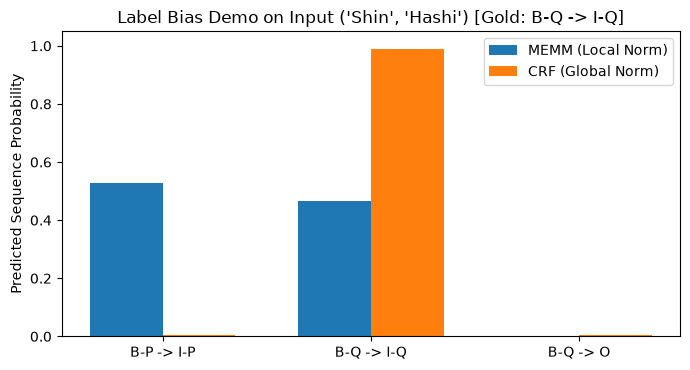

In [5]:
target_x = ("新", "橋")
mp = predict_memm_probs(w_memm, target_x)
cp = predict_crf_probs(w_crf, target_x)

detail_rows = []
for path in ALLOWED_PATHS:
    p1, p2, p_memm = mp[path]
    score_crf, p_crf = cp[path]
    detail_rows.append({
        "候補パス": f"{path[0]} -> {path[1]}",
        "MEMM P(y1|新)": round(p1, 4),
        "MEMM P(y2|y1,橋)": round(p2, 4),
        "MEMM 総確率 P1×P2": round(p_memm, 4),
        "CRF 経路スコア S": round(score_crf, 3),
        "CRF 総確率 exp(S)/Z": round(p_crf, 4),
    })
display(pd.DataFrame(detail_rows))

labels_en = [f"{p[0]} -> {p[1]}" for p in ALLOWED_PATHS]
memm_vals = [mp[p][2] for p in ALLOWED_PATHS]
crf_vals = [cp[p][1] for p in ALLOWED_PATHS]

x_pos = np.arange(len(labels_en))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x_pos - width / 2, memm_vals, width, label="MEMM (Local Norm)")
ax.bar(x_pos + width / 2, crf_vals, width, label="CRF (Global Norm)")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels_en)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Predicted Sequence Probability")
ax.set_title("Label Bias Demo on Input ('Shin', 'Hashi') [Gold: B-Q -> I-Q]")
ax.legend()
plt.tight_layout()
plt.show()

### ポイントの整理

- **MEMM の罠（ラベルバイアス）**: 時刻 2 の確率 $P(y_2 \mid y_1, x_2)$ を「その遷移元 $y_1$ から出られる候補だけ」で局所正規化するため、遷移先が 1 つしかない `B-P` では観測語が「橋」であっても必ず $P(\text{I-P} \mid \text{B-P}, \text{"橋"}) = 1.000$ になってしまいます。結果として、時刻 1 で `45 > 40` の頻度差から `B-P` が少し優位になると、後続の強力な観測情報「橋」を使っても挽回できなくなります。
- **CRF の解決策**: 全パスまとめて 1 つの分配関数 $Z(x)$ で大域正規化するため、各時刻の素性スコア（例：「橋」と `I-Q` の強い共起重み）を系列全体のスコアに直接加算でき、ラベルバイアスを回避して正しいパス `B-Q -> I-Q` を選べます。
- **Viterbi デコーディングとの相性**: 大域正規化モデルの最尤系列探索（$\arg\max_y \sum_t \theta^\top \phi(y_{t-1}, y_t, x_t)$）は、第1節で実装した形態素解析のコスト最小化と数学的に同型の動的計画法（Viterbi アルゴリズム）で効率よく解けます。